# California Housing Regression


## Objective

Predict median California census-block house values and compare a linear baseline with tree ensembles and gradient-boosting models. Model configuration is selected with cross-validation on the training partition; the final test partition is reserved for one unbiased evaluation of the selected model.

## Dataset

The analysis uses `sklearn.datasets.fetch_california_housing`, derived from the 1990 US census. The target is median house value in units of $100,000.

## Method

The notebook retains the original exploratory analysis, pipeline-based preprocessing, model grids, residual analysis, and feature-importance interpretation. The evaluation section was tightened for the portfolio version to separate cross-validation from final test reporting.


In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
# clean plotting style
sns.set_style("whitegrid")
sns.set_context("talk")

## Objectives
1. To predict the median house price of house blocks in California in terms of location, income, and housing features through regression analysis.
2. To compare multiple regression models and select the best model for median house price prediction.
3. To interpret the importance of features for the median house price through the best model.

## Data Description and Loading
The dataset is originally obtained from the US Census of 1990, where income, age, location, housing features, and median house price of different blocks of California were published. A block is the smallest geographical unit for which sample data is provided in the Census.
Data source:
https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html#sklearn.datasets.fetch_california_housing
The data is directly loaded from the scikit-learn module, and its features as well as target are investigated to observe that there are no missing values and all variables are numeric. The brief description of variables is as follows.

    - MedInc        block group median income (in $10,000)
    
    - HouseAge      median house age in block group (years)
    
    - AveRooms      average number of rooms per household
    
    - AveBedrms     average number of bedrooms per household
    
    - Population    block group population
    
    - AveOccup      average number of household members
    
    - Latitude      block group latitude
    
    - Longitude     block group longitude
    
    - MedHouseVal(target)	Median price of houses in the block (in $100,000)

In [2]:
housing = fetch_california_housing(as_frame=True)
X = housing['data']
y = housing['target']

In [3]:
# Combining features and target
data = X.copy()
data["MedHouseVal"] = y
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Exploratory Analysis

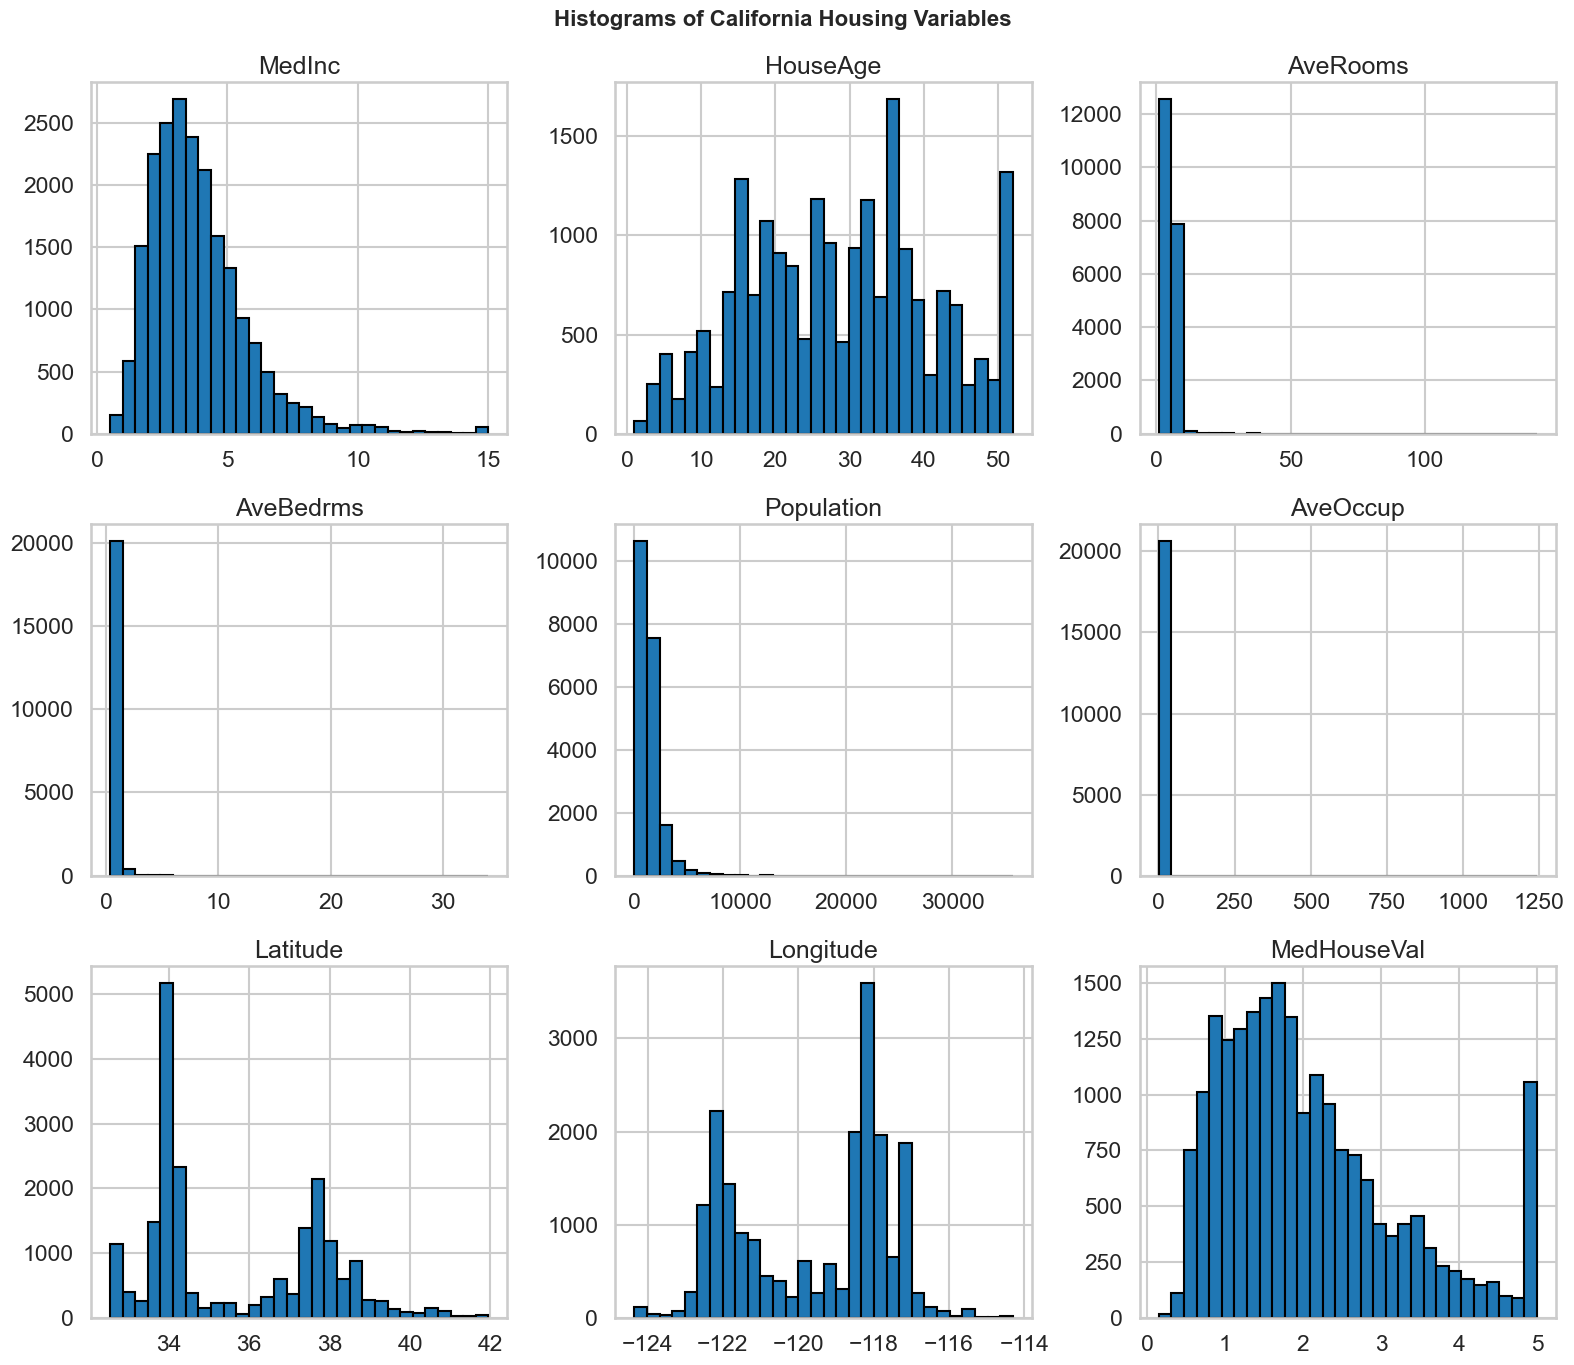

In [4]:
# Histograms for all variables
data.hist(
    figsize=(16, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Histograms of California Housing Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

The histograms show distributions of features with different levels of skewness, with median income and median house block prices having a positively skewed distribution, while features like average number of rooms, bedrooms, and occupancy are extremely positively skewed. Median age of house blocks is slightly negatively skewed, while location attributes like latitude and longitude have high frequencies at a few points, indicating more blocks in those regions.

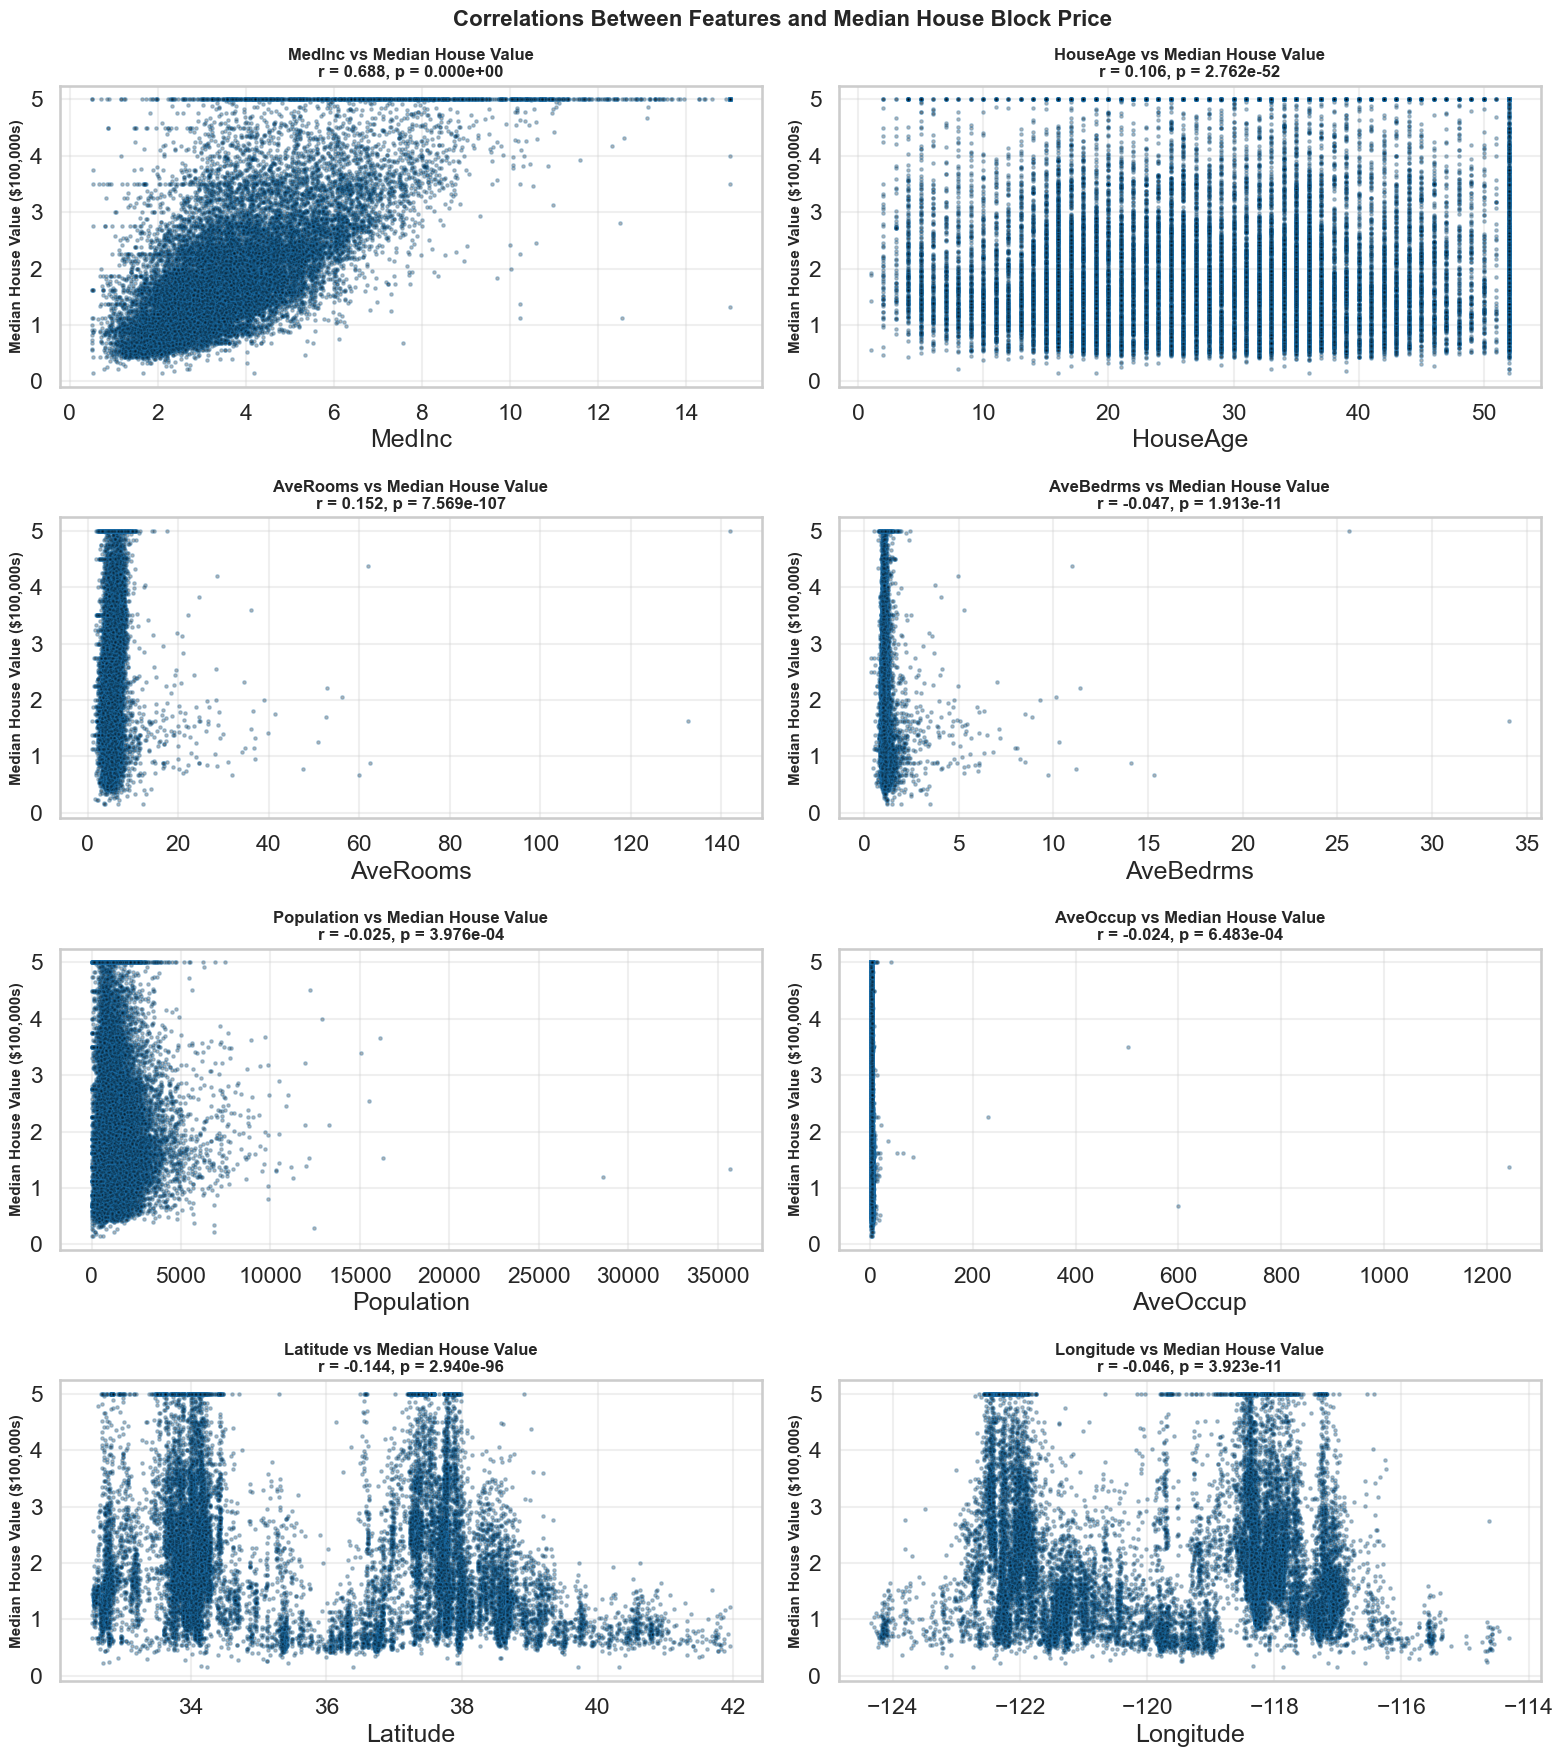

In [5]:
features = X.columns

plt.figure(figsize=(16, 18))

# correlations
for i, feature in enumerate(features, 1):
    r, p = pearsonr(data[feature], data["MedHouseVal"])

    
    plt.subplot(4, 2, i)
    plt.plot(data[feature], data["MedHouseVal"], alpha=0.3, ls='None',marker='.',ms=5,mfc='k')
    plt.title(
        f"{feature} vs Median House Value\nr = {r:.3f}, p = {p:.3e}",
        fontsize=12,
        fontweight="bold"
    )
    plt.xlabel(feature)
    plt.ylabel("Median House Value ($100,000s)", fontsize=11,fontweight="bold")
    plt.grid(alpha=0.3)

plt.suptitle(
    "Correlations Between Features and Median House Block Price",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

The correlation among features and the target attributes shows all features have significant correlation (p-value < 0.05) with median house block price, indicating all features have significant influence on the target and no features are removed while modelling. The correlation coefficient is highest at 0.688 with median income, indicating the income level has the strongest influence on median price and the influence is of moderate level.

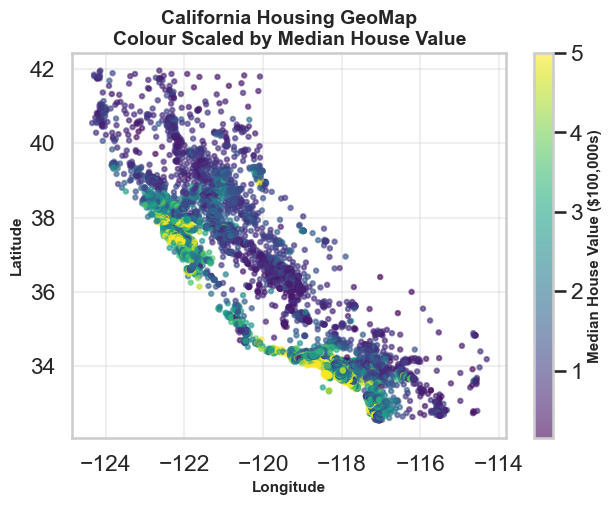

In [6]:
# geographic scatter plot
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    data["Longitude"],
    data["Latitude"],
    c=data["MedHouseVal"],
    cmap="viridis",
    alpha=0.6,
    s=10
)

# colorbar
cbar = plt.colorbar(scatter)
cbar.set_label(
    "Median House Value ($100,000s)",
    fontsize=11,
    fontweight="bold"
)

# Labels and title
plt.title(
    "California Housing GeoMap\nColour Scaled by Median House Value",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Longitude", fontsize=11, fontweight="bold")
plt.ylabel("Latitude", fontsize=11, fontweight="bold")

plt.grid(alpha=0.3)

plt.show()

The geographic distribution of median price shows at few locations, typically near (38, -122) and (34, -118), have a high median house price of around `$0.5M`, while most house blocks in other locations have prices less than `$0.1M`.  

## Regression Modelling

### Train/test split


In [7]:
# Split predictors and target
X_features = data.drop(columns=["MedHouseVal"])
y_target = data["MedHouseVal"]

# Final test data is separated before model fitting or tuning
X_train, X_test, y_train, y_test = train_test_split(
    X_features,
    y_target,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (16512, 8)
Validation shape: (4128, 8)


### Linear Regression

In [8]:
# Store models and evaluation results
fitted_models = {}
results = []

In [9]:
# Linear Regression pipeline
lr_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

fitted_models["Linear Regression"] = lr_model

In [ ]:
# Test evaluation for Linear Regression is intentionally deferred.
# All model comparison and selection below uses cross-validation on X_train only.


### Random Forest Regression

In [11]:
# Random Forest with small grid
rf_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=3
)

rf_grid.fit(X_train, y_train)

fitted_models["Random Forest"] = rf_grid.best_estimator_

print("Best parameters:", rf_grid.best_params_)
print("Best CV MSE:", -rf_grid.best_score_)

Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV 1/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=100;, score=-0.306 total time=   1.6s
[CV 2/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=100;, score=-0.296 total time=   1.6s
[CV 3/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=100;, score=-0.274 total time=   1.7s
[CV 4/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=100;, score=-0.308 total time=   1.8s
[CV 1/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=200;, score=-0.304 total time=   3.7s
[CV 2/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=200;, score=-0.293 total time=   3.9s
[CV 3/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=200;, score=-0.274 total time=   4.2s
[CV 4/4] END model__max_depth=10, model__min_samples_split=2, model__n_estimators=200;, score=-0.307

In [ ]:
# Test evaluation for Random Forest is intentionally deferred.
# All model comparison and selection below uses cross-validation on X_train only.


### Extreme Gradient Boost Regression

In [13]:
# XGBoost grid
xgb_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        verbosity=1
    ))
])

xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    xgb_pipeline,
    xgb_param_grid,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=3
)

xgb_grid.fit(X_train, y_train)

fitted_models["XGBoost"] = xgb_grid.best_estimator_

print("Best parameters:", xgb_grid.best_params_)
print("Best CV MSE:", -xgb_grid.best_score_)

Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV 1/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=100;, score=-0.334 total time=   0.1s
[CV 2/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=100;, score=-0.318 total time=   0.1s
[CV 3/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=100;, score=-0.307 total time=   0.1s
[CV 4/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=100;, score=-0.350 total time=   0.1s
[CV 1/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=200;, score=-0.293 total time=   0.2s
[CV 2/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=200;, score=-0.282 total time=   0.2s
[CV 3/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=200;, score=-0.263 total time=   0.2s
[CV 4/4] END model__learning_rate=0.05, model__max_depth=3, model__n_estimators=200;, score=-0.306 total time=   0

In [ ]:
# Test evaluation for XGBoost is intentionally deferred.
# All model comparison and selection below uses cross-validation on X_train only.


### Light Gradient Boosting Machine Regression

In [15]:
# LightGBM grid
lgbm_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", LGBMRegressor(
        random_state=42,
        verbose=0, force_col_wise=True
    ))
])

lgbm_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [-1, 10],
    "model__learning_rate": [0.05, 0.1]
}

lgbm_grid = GridSearchCV(
    lgbm_pipeline,
    lgbm_param_grid,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=3
)

lgbm_grid.fit(X_train, y_train)

fitted_models["LightGBM"] = lgbm_grid.best_estimator_

print("Best parameters:", lgbm_grid.best_params_)
print("Best CV MSE:", -lgbm_grid.best_score_)

Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV 1/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=100;, score=-0.244 total time=   0.3s
[CV 2/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=100;, score=-0.246 total time=   0.1s
[CV 3/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=100;, score=-0.221 total time=   0.1s
[CV 4/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=100;, score=-0.257 total time=   0.1s
[CV 1/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=200;, score=-0.223 total time=   0.2s
[CV 2/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=200;, score=-0.226 total time=   0.3s
[CV 3/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=200;, score=-0.203 total time=   0.2s
[CV 4/4] END model__learning_rate=0.05, model__max_depth=-1, model__n_estimators=200;, score=-0.233 total t

In [ ]:
# Test evaluation for LightGBM is intentionally deferred.
# All model comparison and selection below uses cross-validation on X_train only.


### CatBoost Regression

In [17]:
# CatBoost grid
cat_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", CatBoostRegressor(
        random_state=42,
        verbose=0,
        loss_function="RMSE"
    ))
])

cat_param_grid = {
    "model__iterations": [100, 200],
    "model__depth": [4, 6],
    "model__learning_rate": [0.05, 0.1]
}

cat_grid = GridSearchCV(
    cat_pipeline,
    cat_param_grid,
    cv=4,
    scoring="neg_mean_squared_error",
    verbose=3
)

cat_grid.fit(X_train, y_train)

fitted_models["CatBoost"] = cat_grid.best_estimator_

print("Best parameters:", cat_grid.best_params_)
print("Best CV MSE:", -cat_grid.best_score_)

Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV 1/4] END model__depth=4, model__iterations=100, model__learning_rate=0.05;, score=-0.352 total time=   0.5s
[CV 2/4] END model__depth=4, model__iterations=100, model__learning_rate=0.05;, score=-0.331 total time=   0.4s
[CV 3/4] END model__depth=4, model__iterations=100, model__learning_rate=0.05;, score=-0.322 total time=   0.4s
[CV 4/4] END model__depth=4, model__iterations=100, model__learning_rate=0.05;, score=-0.364 total time=   0.5s
[CV 1/4] END model__depth=4, model__iterations=100, model__learning_rate=0.1;, score=-0.297 total time=   0.5s
[CV 2/4] END model__depth=4, model__iterations=100, model__learning_rate=0.1;, score=-0.282 total time=   0.4s
[CV 3/4] END model__depth=4, model__iterations=100, model__learning_rate=0.1;, score=-0.267 total time=   0.4s
[CV 4/4] END model__depth=4, model__iterations=100, model__learning_rate=0.1;, score=-0.313 total time=   0.4s
[CV 1/4] END model__depth=4, model__iterations=2

In [ ]:
# Test evaluation for CatBoost is intentionally deferred.
# All model comparison and selection below uses cross-validation on X_train only.


### Model Comparison and Best Model Interpretation

In [ ]:
# Consistent model comparison using five-fold CV on the training partition
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for model_name, estimator in fitted_models.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
        },
        n_jobs=-1,
    )
    cv_rows.append({
        "Model": model_name,
        "CV R2 mean": scores["test_R2"].mean(),
        "CV MAE mean": -scores["test_MAE"].mean(),
        "CV RMSE mean": -scores["test_RMSE"].mean(),
        "CV RMSE std": scores["test_RMSE"].std(),
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV RMSE mean").reset_index(drop=True)
selected_model_name = cv_results_df.loc[0, "Model"]
best_model = fitted_models[selected_model_name]

# The selected estimator was fitted only on X_train; evaluate it once on X_test.
y_pred = best_model.predict(X_test)
test_results_df = pd.DataFrame([{
    "Selected model": selected_model_name,
    "Test R2": r2_score(y_test, y_pred),
    "Test MAE": mean_absolute_error(y_test, y_pred),
    "Test RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
}])

display(cv_results_df.round(4))
display(test_results_df.round(4))


The portfolio evaluation selects the model with the lowest mean cross-validated RMSE on the training partition. Only that selected estimator is then reported on the untouched test set using R², MAE, and RMSE. In the original run, LightGBM remained the strongest model and achieved test R² = 0.8463, MAE = 0.2952, and RMSE = 0.4488. Values are in the dataset target scale (units of $100,000).

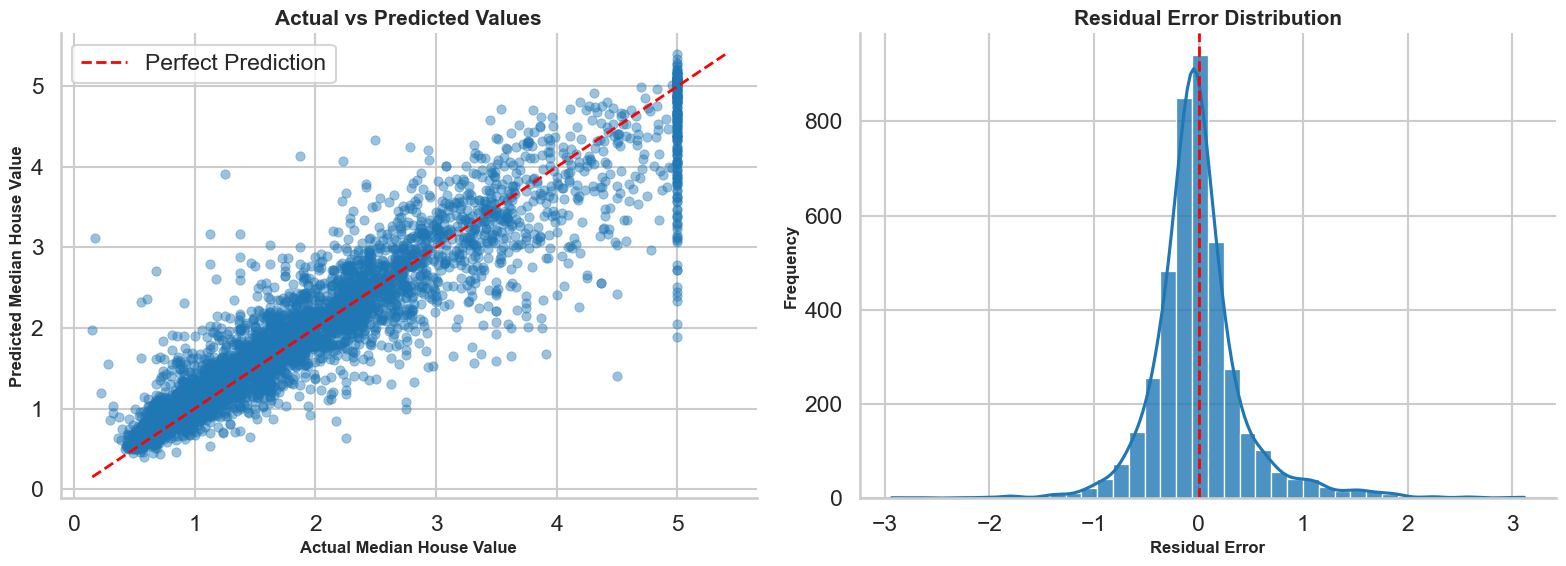

In [20]:
# The selected model and test predictions were produced in the preceding cell.

# Residuals
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


# Actual vs Predicted Plot

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.45,
    s=45,
    edgecolor=None,
    ax=axes[0]
)

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    color="red",
    label="Perfect Prediction"
)

axes[0].set_title(
    "Actual vs Predicted Values",
    fontsize=15,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Actual Median House Value",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Predicted Median House Value",
    fontsize=12,
    fontweight="bold"
)

axes[0].legend()


# Residual Distribution Plot

sns.histplot(
    residuals,
    bins=40,
    kde=True,
    alpha=0.8,
    ax=axes[1]
)

axes[1].axvline(
    0,
    linestyle="--",
    linewidth=2,
    color="red"
)

axes[1].set_title(
    "Residual Error Distribution",
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Residual Error",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Frequency",
    fontsize=12,
    fontweight="bold"
)

sns.despine()

plt.tight_layout()
plt.show()

With the best model, LightGBM, the actual and predicted median prices seem to mostly align with the perfect prediction diagonal line, with some deviations mostly observed for very high prices around `$0.5M`. The Residual distribution shows errors are approximately normally distributed with a peak around the zero-error line.

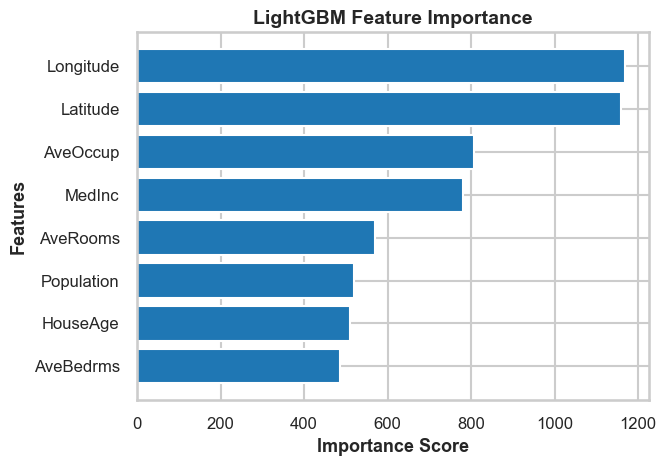

In [25]:
# The original analysis selected LightGBM; inspect its fitted feature importances.
lgbm_model = fitted_models["LightGBM"].named_steps["model"]

# Feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgbm_model.feature_importances_
})

# Sort values
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

# Plot feature importance
plt.figure(figsize=(7, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title(
    "LightGBM Feature Importance",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Importance Score", fontsize=13, fontweight="bold")
plt.ylabel("Features", fontsize=13, fontweight="bold")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

According to the best model, longitude and latitude have the highest feature importance, followed by average number of household members and median income level of the block of houses. Other features like average number of rooms, average population, median age of houses in the block, and average number of bedrooms in the houses have low importance for median block price.

## Limitations

- The dataset is a 1990 census benchmark and does not represent current California housing conditions.
- Random splitting does not test geographic or temporal transfer.
- Tree feature importance measures split usage, not causal influence.
- XGBoost, LightGBM, and CatBoost are optional dependencies and may differ slightly by library version.

## Conclusion

Non-linear ensembles substantially outperform the linear baseline. Cross-validation is used for comparison and tuning, while the final test set provides a single estimate of generalization for the selected model. The result supports the original conclusion that location, income, and non-linear interactions are important for this benchmark.
